In [105]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tabulate import tabulate
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, BayesianRidge, PoissonRegressor, Ridge, SGDClassifier, HuberRegressor, QuantileRegressor, Lasso, ElasticNet
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)  
pd.set_option('display.max_columns', None)  
pd.set_option('display.expand_frame_repr', False)

## Utility Functions

In [51]:
def load_node_profile(node):
    filepath = f'../../tool/infrastructure-profiler/profiles/{node}.csv'

    with open(filepath) as f:
        data = f.readlines()[1].split(',')

    return {
        'ram': int(data[1].strip()),
        'cores': int(data[2].strip()),
        'io_read': float(data[3].strip()),
        'io_write': float(data[4].strip()),
        'sysbench': float(data[5].strip()),
        'z7b': float(data[6].strip()),
        'bench_time': float(data[7].strip())
    }

def combine_df(input_df, trace_df):
    rows = []

    for name, group in input_df.groupby('name'):
        no_files = str(len(group))
        filepaths = group['path']
        paths = ','.join([filepath.split('/')[-1].split('.')[-1] for filepath in filepaths])
        total_size = group['size'].sum() / 1073741824  # convert from B to GiB

        if len(trace_df[trace_df['name'] == name]) > 0:
            task_record = trace_df[trace_df['name'] == name].iloc[0]
            task_realtime = task_record['realtime']
            task_difftime = task_record['complete'] - task_record['start']
            task_memory = task_record['memory'] / 1073741824  # convert from B to GiB
            if task_difftime > (1.2 * task_realtime):
                task_runtime = task_realtime
            else:
                task_runtime = task_realtime
            short_name = task_record['name'].split(':')[-2] + ':' + task_record['name'].split(':')[-1].split(' ')[0]
            row = [task_record['task_id'], task_record['name'], task_record['%cpu'], 
                task_record['start'], task_record['complete'], task_runtime, 
                no_files, paths, total_size, short_name, task_record['hostname'], task_memory]
            rows.append(row) 
        else:
            print('err:', name)

    combined = pd.DataFrame(rows, columns=['id', 'name', '%cpu', 'start', 'complete', 'runtime', 'no_files', 'files', 'input_gib', 'short_name', 'hostname', 'memory'])
    return combined

def load_profiling_runs(node, workflows, samples, node_profiles):
    node_profile = node_profiles[node]
    runs = {}

    for workflow, samples in zip(workflows, samples):
        runs[workflow] = {}

        for sample in samples:
            sample_dir = f'{node}/{workflow}/{sample}/'
            input_df = pd.read_csv(sample_dir + 'input.csv', sep=';')
            trace_df = pd.read_csv(sample_dir + 'trace.csv')
            runs[workflow][sample] = combine_df(input_df, trace_df)

    return (node_profile, runs)

def load_workflow_execution(cluster, workflow, iteration):
    execution_dir = f'../{cluster}/{workflow}/{iteration}/'
    input_df = pd.read_csv(execution_dir + 'input.csv', sep=';')
    trace_df = pd.read_csv(execution_dir + 'trace.csv')
    return combine_df(input_df, trace_df)

def load_ichnos_trace(cluster, workflow, iteration, gov):
    short_cluster = cluster.split('-')[0]
    trace_loc = f'../{cluster}/{workflow}/ichnos/{short_cluster}-{workflow}-{iteration}-1-{gov}-trace.csv'
    return pd.read_csv(trace_loc)

def process_ichnos_summary(raw):
    core_total_energy = float(raw[7].split(': ')[-1][:-3])
    mem_dynamic_energy = float(raw[9].split(': ')[-1][:-3])
    mem_static_energy = float(raw[15].split(': ')[-1][:-3])
    return {
        'core_total': core_total_energy, 
        'mem_dynamic': mem_dynamic_energy, 
        'mem_static': mem_static_energy, 
        'total': core_total_energy + mem_dynamic_energy + mem_static_energy
    } 

def load_ichnos_summary(cluster, workflow, iteration, gov):
    short_cluster = cluster.split('-')[0]
    with open(f'../{cluster}/{workflow}/ichnos/{short_cluster}-{workflow}-{iteration}-1-{gov}-summary.txt', 'r') as file:
        raw = file.readlines()
    raw = [line.strip() for line in raw]
    return process_ichnos_summary(raw)

def load_rapl_summary(cluster, workflow, iteration):
    rapl_vals = pd.read_csv(f'../{cluster}/{workflow}-runs.csv')
    return rapl_vals.iloc[[iteration - 1]]

def load_power_model(node, setting=''):
    if setting != '':
        filename = f'{setting}-model.txt'
    else: 
        filename = 'model.txt'

    with open(f'../../tool/infrastructure-profiler/raw/{node}/{filename}', 'r') as f:
        data = [line.strip() for line in f.readlines()[1:]]

    coeff = float(data[0].split(',')[0][2:].strip())
    inter = float(data[0].split(',')[1][:-2].strip())
    draw = float(data[1].split(':')[1].strip())

    if draw == 0:
        draw = 0.392

    return (coeff, inter, draw)

def get_task_data_from_experiment(task_name, experiment):
    task_data = experiment[experiment['short_name'] == task_name]
    key_data = task_data[['input_gib', 'runtime', '%cpu']]
    key_data.columns = ['data', 'time', 'usage']
    key_data.reset_index().drop('index', axis=1)
    return key_data

def get_error(predicted, actual):
    return abs(actual - predicted) / actual * 100

In [52]:
class MedianModel:
    def __init__(self, median):
        self.median = median
    
    def predict(self, x):
        x = np.asarray(x)
        value = x.shape[0]
        return np.full(value, self.median)

## Setup Data

In [53]:
# Constants
HU = 'hu'
HU_40 = 'hu-c40'
HU_42 = 'hu-c42'
HU_44 = 'hu-c44'
HU_45 = 'hu-c45'
GPG = 'gpg'
GPG_13 = 'gpgnode-13'
GPG_14 = 'gpgnode-14'
GPG_15 = 'gpgnode-15'
GPG_16 = 'gpgnode-16'
GPG_17 = 'gpgnode-17'
GPG_18 = 'gpgnode-18'
GPG_22 = 'gpgnode-22'
AWS = 'aws'
AWS_m5_4xl = 'aws-m5-4xl'
AWS_c5d = 'aws-metal-c5d'
GCP_n2 = 'gcp-n2'
wfs = {
    GPG: ['rnaseq', 'chipseq', 'nanoseq', 'atacseq'], 
    HU: ['rnaseq', 'chipseq', 'nanoseq', 'atacseq']
}
VR = 'VR'
RF = 'RandomForest'
LR = 'LinearRegression'
BR = 'BayesianRidge'
PR = 'PoissonRegressor'
GBR = 'GradientBoostingRegressor'
RIDGE = 'Ridge'
SGD = 'StochasticGradientDescent'
HR = 'HuberRegressor'
QR = 'QuantileRegressor'
LASSO = 'Lasso'

In [54]:
# Node Profiles + Power Models (todo)
nodes = [GPG_13, GPG_14, GPG_15, GPG_16, GPG_17, GPG_18, GPG_22, HU_40, HU_42, AWS_c5d, HU_44, HU_45, AWS_m5_4xl]
node_profiles = {}

for node in nodes:
    profile = load_node_profile(node)
    node_profiles[node] = profile

nodes_by_host = {
    'hu-worker-c40': HU_40,
    'hu-worker-c42': HU_42,
    'hu-worker-c44': HU_44,
    'hu-worker-c45': HU_45
}

gov_by_workflow = {
    GPG: {
        "rnaseq": "ondemand_linear",
        "chipseq": "ondemand_linear",
        "nanoseq": "ondemand_linear",
        "atacseq": "ondemand_linear"
    },
    HU: {
        "rnaseq": "schedutil_linear",
        "chipseq": "schedutil_linear",
        "rangeland": "schedutil_linear",
        "sarek": "schedutil_linear",
        "nanoseq": "performance_linear",
        "atacseq": "performance_linear"
    }
}

In [55]:
# Workflow Executions 
wf_executions = {}

for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    wf_executions[cluster] = {}
    for wf in wfs[cluster]:
        wf_executions[cluster][wf] = {}
        for iteration in range(1, 4):
            wf_executions[cluster][wf][iteration] = {}
            wf_executions[cluster][wf][iteration]['run'] = load_workflow_execution(cluster_path, wf, iteration)

In [56]:
# Workflow RAPL Total
for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    for wf in wfs[cluster]:
        for iteration in range(1, 4):
            wf_executions[cluster][wf][iteration]['rapl'] = load_rapl_summary(cluster_path, wf, iteration)

In [57]:
# Workflow Ichnos Total
for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    for wf in wfs[cluster]:
        for iteration in range(1, 4):
            wf_executions[cluster][wf][iteration]['ichnos'] = load_ichnos_summary(cluster_path, wf, iteration, gov_by_workflow[cluster][wf])

In [58]:
# Join Workflow Traces with Ichnos Traces 
def add_energy_with_task_id(run, ichnos):
    combined = pd.merge(run, ichnos[['id', 'core_kwh', 'mem_kwh']], on='id').drop_duplicates()
    return combined[['id', 'name', '%cpu', 'start', 'complete', 'runtime', 'no_files', 'files', 'input_gib', 'short_name', 'hostname', 'core_kwh', 'mem_kwh', 'memory']]

# Workflow Ichnos Total
for cluster, cluster_path in zip([GPG, HU], ['gu-cluster', 'hu-cluster']):
    for wf in wfs[cluster]:
        for iteration in range(1, 4):
            run = wf_executions[cluster][wf][iteration]['run']
            ichnos_trace = load_ichnos_trace(cluster_path, wf, iteration, gov_by_workflow[cluster][wf])
            df_with_energy = add_energy_with_task_id(run, ichnos_trace)
            wf_executions[cluster][wf][iteration]['run'] = df_with_energy

In [59]:
# Compare RAPL Total to Ichnos Total
gu_socket = {'rnaseq': '_2', 'chipseq': '_2', 'nanoseq': 'both', 'atacseq': 'both'}
hu_socket = {'rnaseq': '', 'chipseq': '', 'nanoseq': '', 'atacseq': ''}

for cluster, cluster_path, socket in zip([GPG, HU], ['gu-cluster', 'hu-cluster'], [gu_socket, hu_socket]):
    print('===', cluster, '===')
    for wf in wfs[cluster]:
        all_ichnos = []
        all_rapl = []

        for iteration in range(1, 4):
            ichnos_total = wf_executions[cluster][wf][iteration]['ichnos']['total']
            ichnos_core = wf_executions[cluster][wf][iteration]['ichnos']['core_total']
            ichnos_mem = wf_executions[cluster][wf][iteration]['ichnos']['mem_dynamic'] + wf_executions[cluster][wf][iteration]['ichnos']['mem_static']

            rapl_socket = socket[wf]
            if rapl_socket == 'both':
                rapl_core = wf_executions[cluster][wf][iteration]['rapl'][f'active_pkg_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'active_pkg_2'].iloc[0]

                if wf_executions[cluster][wf][iteration]['rapl'][f'idle_dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'idle_dram_2'].iloc[0] > wf_executions[cluster][wf][iteration]['rapl'][f'dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'dram_2'].iloc[0]:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'dram_2'].iloc[0]
                else:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'active_dram_1'].iloc[0] + wf_executions[cluster][wf][iteration]['rapl'][f'active_dram_2'].iloc[0]
            else:
                rapl_core = wf_executions[cluster][wf][iteration]['rapl'][f'active_pkg{rapl_socket}'].iloc[0]

                if wf_executions[cluster][wf][iteration]['rapl'][f'idle_dram{rapl_socket}'].iloc[0] > wf_executions[cluster][wf][iteration]['rapl'][f'dram{rapl_socket}'].iloc[0]:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'dram{rapl_socket}'].iloc[0]
                else:
                    rapl_mem = wf_executions[cluster][wf][iteration]['rapl'][f'active_dram{rapl_socket}'].iloc[0]

            rapl_total = rapl_core + rapl_mem
            wf_executions[cluster][wf][iteration]['rapl']['core'] = rapl_core
            wf_executions[cluster][wf][iteration]['rapl']['mem'] = rapl_mem
            core_error = abs(rapl_core - ichnos_core) / rapl_core * 100
            mem_error = abs(rapl_mem - ichnos_mem) / rapl_mem * 100
            total_error = abs(rapl_total - ichnos_total) / rapl_total * 100

            #print(f'{wf}-{iteration} ichnos: {ichnos_total:.2f}kWh rapl: {rapl_total:.2f}kWh error {total_error:.2f}%')
            all_ichnos.append(ichnos_total)
            all_rapl.append(rapl_total)
        avg_ichnos = np.mean(all_ichnos)
        avg_rapl = np.mean(all_rapl)

        print(f'{wf} i: {avg_ichnos:.2f}kWh, r: {avg_rapl:.2f}kWh, {get_error(avg_ichnos, avg_rapl):.2f}%')

=== gpg ===
rnaseq i: 1.52kWh, r: 1.43kWh, 6.99%
chipseq i: 2.00kWh, r: 1.90kWh, 5.64%
nanoseq i: 0.88kWh, r: 0.98kWh, 10.56%
atacseq i: 1.43kWh, r: 1.53kWh, 6.38%
=== hu ===
rnaseq i: 2.28kWh, r: 2.54kWh, 10.20%
chipseq i: 4.68kWh, r: 5.16kWh, 9.22%
nanoseq i: 0.42kWh, r: 0.51kWh, 16.31%
atacseq i: 0.61kWh, r: 0.67kWh, 9.95%


In [60]:
# Load workflow profiling runs
wf_profiles = {}

# HU_40
wfs = ['rnaseq', 'chipseq', 'nanoseq', 'atacseq']
samples = [['sample_a', 'sample_b', 'sample_c', 'sample_d', 'sample_e'], 
           ['sample_f', 'sample_g', 'sample_h', 'sample_i', 'sample_j'],
           ['sample_k', 'sample_l', 'sample_m', 'sample_n', 'sample_o'], 
           ['sample_p', 'sample_q', 'sample_r', 'sample_s', 'sample_t']]
profile, runs = load_profiling_runs(HU_40, wfs, samples, node_profiles)
wf_profiles[HU_40] = {
    'node_profile': profile,
    'executions': runs,
    'power_model': load_power_model(HU_40, 'schedutil')
}

# HU_42
wfs = ['rnaseq', 'chipseq']
samples = [['sample_a', 'sample_b', 'sample_c', 'sample_d', 'sample_e'], 
           ['sample_g', 'sample_h', 'sample_i', 'sample_j']]  
profile, runs = load_profiling_runs(HU_42, wfs, samples, node_profiles)
wf_profiles[HU_42] = {
    'node_profile': profile,
    'executions': runs,
    'power_model': load_power_model(HU_42, 'schedutil')
}

HU_44
wfs = ['rnaseq', 'chipseq']
samples = [['sample_a', 'sample_b', 'sample_c', 'sample_d', 'sample_e'], 
           ['sample_f', 'sample_g', 'sample_h', 'sample_i', 'sample_j']]  
profile, runs = load_profiling_runs(HU_44, wfs, samples, node_profiles)
wf_profiles[HU_44] = {
    'node_profile': profile,
    'executions': runs,
    'power_model': load_power_model(HU_44, 'schedutil')
}

HU_45
wfs = ['rnaseq', 'chipseq']
samples = [['sample_a', 'sample_b', 'sample_c', 'sample_d', 'sample_e'], 
           ['sample_f', 'sample_g', 'sample_h', 'sample_i', 'sample_j']]  
profile, runs = load_profiling_runs(HU_45, wfs, samples, node_profiles)
wf_profiles[HU_45] = {
    'node_profile': profile,
    'executions': runs,
    'power_model': load_power_model(HU_45, 'schedutil')
}

# gpgnode-13
wf_profiles[GPG_13] = {
    'node_profile': node_profiles[GPG_13],
    'power_model': load_power_model(GPG_13, 'ondemand')
}

# gpgnode-14
wf_profiles[GPG_14] = {
    'node_profile': node_profiles[GPG_14],
    'power_model': load_power_model(GPG_14, 'ondemand')
}

# gpgnode-15
wf_profiles[GPG_15] = {
    'node_profile': node_profiles[GPG_15],
    'power_model': load_power_model(GPG_15, 'ondemand')
}

# gpgnode-16
wf_profiles[GPG_16] = {
    'node_profile': node_profiles[GPG_16],
    'power_model': load_power_model(GPG_16, 'ondemand')
}

# gpgnode-17
wf_profiles[GPG_17] = {
    'node_profile': node_profiles[GPG_17],
    'power_model': load_power_model(GPG_17, 'ondemand')
}

# gpgnode-18
wfs = ['rnaseq', 'chipseq', 'nanoseq', 'atacseq']
samples = [['sample_a', 'sample_b', 'sample_c', 'sample_d', 'sample_e'], 
           ['sample_f', 'sample_g', 'sample_h', 'sample_i', 'sample_j'], 
           ['sample_k', 'sample_l', 'sample_m', 'sample_n', 'sample_o'], 
           ['sample_p', 'sample_q', 'sample_r', 'sample_s', 'sample_t']]
profile, runs = load_profiling_runs(GPG_18, wfs, samples, node_profiles)
wf_profiles[GPG_18] = {
    'node_profile': node_profiles[GPG_18],
    'executions': runs,
    'power_model': load_power_model(GPG_18, 'ondemand')
}

# AWS metal c5d
wfs = ['rnaseq', 'chipseq', 'nanoseq', 'atacseq']
samples = [['sample_a', 'sample_b', 'sample_c', 'sample_d', 'sample_e'], 
           ['sample_g', 'sample_h', 'sample_i', 'sample_j'], 
           ['sample_k', 'sample_l', 'sample_m', 'sample_n', 'sample_o'], 
           ['sample_p', 'sample_q', 'sample_r', 'sample_s', 'sample_t']]
profile, runs = load_profiling_runs(AWS_c5d, wfs, samples, node_profiles)
wf_profiles[AWS_c5d] = {
    'node_profile': node_profiles[AWS_c5d],
    'executions': runs,
    'power_model': load_power_model(AWS_c5d)
}

wfs = ['rnaseq', 'chipseq', 'nanoseq', 'atacseq']
samples = [['sample_a', 'sample_b', 'sample_c', 'sample_d', 'sample_e'], 
           ['sample_f', 'sample_g', 'sample_h', 'sample_i', 'sample_j'],
           ['sample_k', 'sample_l', 'sample_m', 'sample_n', 'sample_o'], 
           ['sample_p', 'sample_q', 'sample_r', 'sample_s', 'sample_t']]
profile, runs = load_profiling_runs(AWS_m5_4xl, wfs, samples, node_profiles)
wf_profiles[AWS_m5_4xl] = {
    'node_profile': node_profiles[AWS_m5_4xl],
    'executions': runs,
    # no power model it's a VM
}

err: NFCORE_CHIPSEQ:CHIPSEQ:IGV
err: NFCORE_CHIPSEQ:CHIPSEQ:IGV


In [61]:
# @Vasilis
# profiling data -- mini executions using downsampled data on a single node
for node in wf_profiles.keys():
    if 'executions' in wf_profiles[node]:
        print(wf_profiles[node]['executions']['rnaseq'])
        # print(wf_profiles[node]['executions']['chipseq'])
        # print(wf_profiles[node]['executions']['nanoseq'])

# workflow data -- full executions on a cluster 
for cluster, workflows in zip([HU, GPG], [['rnaseq', 'chipseq', 'nanoseq'], ['rnaseq', 'chipseq', 'nanoseq']]):
    for workflow in workflows:
        print(wf_executions[cluster][workflow][1]['run']) # run 1, 2 and 3 

{'sample_a':     id                                               name   %cpu          start       complete  runtime no_files                                              files  input_gib                                         short_name hostname  memory
0    2  NFCORE_RNASEQ:PREPARE_GENOME:CUSTOM_GETCHROMSI...   99.9  1769782517205  1769782525838     8000        1                                                 fa   2.931141                PREPARE_GENOME:CUSTOM_GETCHROMSIZES        -     6.0
1    1  NFCORE_RNASEQ:PREPARE_GENOME:GTF_FILTER (genom...   99.8  1769782517204  1769782532517    14000        2                                             gtf,fa   3.784320                          PREPARE_GENOME:GTF_FILTER        -     6.0
2    6  NFCORE_RNASEQ:PREPARE_GENOME:MAKE_TRANSCRIPTS_...  100.1  1769782532617  1769782576731    42250        2                                             gtf,fa   3.711849              PREPARE_GENOME:MAKE_TRANSCRIPTS_FASTA        -    72.0
3    7  NFCORE_

## Evaluation

In [132]:
# Augur Functions
def find_closest_key(task_name, dictionary):
    task_end = task_name.split(':')[-1]
    match = ''

    for key in list(dictionary.keys()):
        key_end = key.split(':')[-1]
        if key_end == task_end:
            match = key

    return match

def compute_active_time_per_host(execution):
    tasks_by_host = {}

    for _, record in execution.iterrows():
        host = record['hostname']
        start_ts = record['start']
        end_ts = record['complete']

        if host in tasks_by_host:
            tasks_by_host[host].append((start_ts, end_ts))
        else:
            tasks_by_host[host] = [(start_ts, end_ts)]

    active_time_by_host = {}

    for host, intervals in tasks_by_host.items():
        if not intervals:
            continue

        intervals.sort(key=lambda x: x[0])  # sort by start timestamp
        merged = []
        current_start, current_end = intervals[0]

        for start, end in intervals[1:]:
            if start <= current_end:  # overlap or contiguous
                current_end = max(current_end, end)
            else:
                merged.append((current_start, current_end))
                current_start, current_end = start, end
        merged.append((current_start, current_end))

        total_ms: float = sum(end - start for start, end in merged)
        active_time_by_host[host] = total_ms / 1000 / 3600  # return time in hours

    return active_time_by_host

def get_translation_factor(local_profile, target_profile):
    local_write_val = local_profile['io_write'] / local_profile['ram']
    local_read_val = local_profile['io_read'] / local_profile['ram']
    target_write_val = target_profile['io_write'] / target_profile['ram']
    target_read_val = target_profile['io_read'] / target_profile['ram']
    cpu_part = (0.5 * (target_profile['z7b'] / local_profile['z7b'])) 
    + (0.5 * (local_profile['sysbench'] / target_profile['sysbench']))
    mem_part = (0.5 * (local_write_val / target_write_val)) + (0.5 * (local_read_val / target_read_val))

    if local_profile['cores'] != target_profile['cores']:
        target = (0.5 * (0.5 * cpu_part) + (0.5 * mem_part)) + (0.5 * (local_profile['cores'] / target_profile['cores']))
    else:
        target = (0.5 * cpu_part) + (0.5 * mem_part)

    return target

def get_task_data_from_cluster_runs(runs, exclude_workflow):
    all_task_data = {}

    for workflow in runs.keys():
        if workflow == exclude_workflow:
            continue

        iterations = range(1, 4)
        tasks = runs[workflow][iterations[0]]['run']['short_name'].unique()

        for task in tasks:
            task_data = pd.DataFrame(columns=['data', 'time', 'usage'], dtype='float64')
            for iteration in iterations:
                experiment_data = get_task_data_from_experiment(task, runs[workflow][iteration]['run'])
                task_data = pd.concat([task_data, experiment_data])

            all_task_data[task] = task_data

    return all_task_data

def get_model(model_type):
    if model_type == BR:
        model = BayesianRidge(fit_intercept=True)
    elif model_type == GBR:
        model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3)
    elif model_type == VR:
        model = SVR()
    elif model_type == RF:
        model = RandomForestRegressor()
    elif model_type == PR:
        model = PoissonRegressor(fit_intercept=True)
    elif model_type == RIDGE:
        model = Ridge(fit_intercept = True)
    elif model_type == SGD:
        model = SGDClassifier(fit_intercept=True)
    elif model_type == QR:
        model = QuantileRegressor(fit_intercept=True)
    elif model_type == HR:
        model = HuberRegressor(fit_intercept=True)
    elif model_type == LASSO:
        model = Lasso(fit_intercept=True)
    else:
        model = LinearRegression()

    return model

In [146]:
# @Vasilis -- latest version of prediction model combining profiling runs with workflow executions (of other workflows)
def train_task_prediction_model(training_data, model_type, backup_models, reflector):
    variance = np.std(training_data['data'])
    pearson = np.corrcoef(training_data['data'].to_numpy(), training_data['time'].to_numpy())[0, 1]

    # case 1: no relationship
    if np.isnan(pearson) or pearson < 0.5:  
        model = MedianModel(np.median(training_data['time'].to_numpy())) 
        model_type = 'Median'
    # case 2: weak linear relationship
    elif pearson < 0.75:
        model = get_model(backup_models[0])
        model = model.fit(training_data['data'].values.reshape(-1, 1), training_data['time'].values) 
        model_type = 'Weak Linear Rel.'
    # case 3: low variance
    elif variance < 0.04:
        model = get_model(backup_models[1])
        model = model.fit(training_data['data'].values.reshape(-1, 1), training_data['time'].values) 
        model_type = 'Low Variance'
    # case 4: strong linear relationship
    else:
        model = get_model(model_type)
        model = model.fit(training_data['data'].values.reshape(-1, 1), training_data['time'].values) 
        model_type = model_type

    if reflector:
        model_type += '**'

    return (model, model_type, variance, pearson)


def create_prediction_model_with_reflections(profiling_runs, model_type, cluster_runs, exclude_workflow, local_profile, target_profile, backup_models=(QR, LASSO), reflector=True):
    factor = get_translation_factor(local_profile, target_profile)
    models, reflector_data = {}, {}

    if reflector:
        reflector_data = get_task_data_from_cluster_runs(cluster_runs, exclude_workflow)

    for workflow in profiling_runs.keys():
        models[workflow] = {}
        samples = list(profiling_runs[workflow].keys()) 
        tasks = profiling_runs[workflow][samples[0]]['short_name'].unique() 

        for task in tasks:
            task_profiling_data = pd.DataFrame(columns=['data', 'time', 'usage'], dtype='float64')
            for sample in samples: 
                experiment_data = get_task_data_from_experiment(task, profiling_runs[workflow][sample])
                task_profiling_data = pd.concat([task_profiling_data, experiment_data])

            models[workflow][task] = {}
            models[workflow][task]['data_profiling'] = task_profiling_data

            # @Vasilis where reflector data is added to the task data
            if task in reflector_data.keys():
                tmp_reflector_data = reflector_data.pop(task)
                tmp_reflector_data['time'] = tmp_reflector_data['time'] / factor
                models[workflow][task]['data_reflector'] = tmp_reflector_data
                models[workflow][task]['reflector'] = True
                models[workflow][task]['usage'] = np.mean(tmp_reflector_data['usage'])
                training_data = pd.concat([models[workflow][task]['data_reflector'], models[workflow][task]['data_profiling']])
            else:
                models[workflow][task]['data_reflector'] = None
                models[workflow][task]['reflector'] = False
                models[workflow][task]['usage'] = np.mean(task_profiling_data['usage'])
                training_data = models[workflow][task]['data_profiling']
                models[workflow][task]['model_type'] = model_type

            (model, tyype, variance, pearson) = train_task_prediction_model(training_data, model_type, backup_models, models[workflow][task]['reflector'])
            models[workflow][task]['model'] = model
            models[workflow][task]['model_type'] = tyype
            models[workflow][task]['variance'] = variance
            models[workflow][task]['pearson'] = pearson

    reflector_models = {}
    for task in reflector_data:
        (model, tyype, variance, pearson) = train_task_prediction_model(reflector_data[task], model_type, backup_models, True)
        reflector_models[task] = {
            'model': model, 
            'model_type': tyype + 'REFLECT-ONLY', 
            'usage': np.mean(reflector_data[task]['usage']),
            'variance': variance,
            'pearson': pearson}

    return (models, reflector_models)

In [136]:
# Prediction and Verification
headers = ['task', 'in (GiB)', 'pred_t (s)', 'scaled_pred_t', 'actual_t', 'raw_error', 'scaled_error', 
           'pred_u (%)', 'actual_u', 'pred_cpu', 'actual_cpu', 'pred_mem', 'actual_mem', 
           'node', 'files', 'no_files', 'variance', 'type', 'pearson', 'energy_error']

def predict_wf(wf_model, workflow, local_profile, reflector_data=None): 
    data, overall_error, energy_error, raw_error_t, missing_tasks = [], [], [], [], []
    actual_execution = workflow['run']

    for _, record in actual_execution.iterrows():
        task_name = record['short_name']
        data_size = record['input_gib']
        node = record['hostname']
        actual_runtime = record['runtime']
        actual_usage = record["%cpu"]

        # task must run for at least 9 seconds
        if actual_runtime > 9000:  
            model_data = None

            if task_name not in wf_model.keys():
                closest_key = find_closest_key(task_name, wf_model)

                if closest_key == '':
                    if reflector_data is None:
                        missing_tasks.append(task_name)
                        continue

                    reflect_key = find_closest_key(task_name, reflector_data)
                    if reflect_key == '':
                        missing_tasks.append(task_name)
                        continue

                    model_data = reflector_data[reflect_key]
                else:
                    model_data = wf_model[closest_key]
            else:
                model_data = wf_model[task_name]

            prediction_model = model_data['model']
            pred_usage = model_data['usage']
            variance = model_data['variance']
            model_type = model_data['model_type']
            pearson = model_data['pearson']

            if node not in wf_profiles.keys():
                node = nodes_by_host[node]

            target_profile = wf_profiles[node]['node_profile']
            factor = get_translation_factor(local_profile, target_profile)
            target_power_model = wf_profiles[node]['power_model']
            predicted_runtime_raw = prediction_model.predict([[data_size]])[0] 
            predicted_runtime = predicted_runtime_raw * factor  

            if predicted_runtime < 15000:
                predicted_runtime = 15000  # minimum predicted task runtime

            error = (abs(predicted_runtime - actual_runtime) / actual_runtime) * 100 
            overall_error.append(error)
            raw_error = (abs(predicted_runtime_raw - actual_runtime) / actual_runtime) * 100 
            raw_error_t.append(raw_error)

            # estimate energy consumption (ichnos logic)
            time_h = predicted_runtime / 1000 / 3600  # convert from ms to hours
            cpu_usage = pred_usage / target_profile['cores'] # energy calculation logic NOT CPU PREDICTION %
            core_consumption = time_h * (target_power_model[0] * cpu_usage) * 0.001
            mem_consumption = record['memory'] * target_power_model[2] * time_h * 0.001
            predicted_energy = core_consumption + mem_consumption
            actual_energy = record['core_kwh'] + record['mem_kwh']

            if actual_energy > 0 and predicted_energy > 0:
                energy_error.append(get_error(predicted_energy, actual_energy))

            # report
            data.append([task_name, data_size, predicted_runtime_raw / 1000, predicted_runtime / 1000, actual_runtime / 1000, raw_error, error, 
                         pred_usage, actual_usage, core_consumption, record['core_kwh'], mem_consumption, record['mem_kwh'], node, record['files'], 
                         record['no_files'], variance, model_type, pearson, get_error(predicted_energy, actual_energy)])

    task_runtime_error = np.mean(overall_error)
    task_energy_error = np.mean(energy_error)
    total_cpu_static_energy = 0.0
    total_mem_static_energy = 0.0
    active_time_per_host = compute_active_time_per_host(actual_execution)
    for host in active_time_per_host.keys():
        total_cpu_static_energy += active_time_per_host[host] * target_power_model[1] * 0.001  # convert to kWh
        total_mem_static_energy += active_time_per_host[host] * target_power_model[2] * target_profile['ram'] * 0.001 # convert to kWh

    data_df = pd.DataFrame(data, columns=headers)
    cpu_dynamic_energy = data_df['pred_cpu'].sum()
    mem_dynamic_energy = data_df['pred_mem'].sum()
    real_dynamic_energy = data_df['actual_cpu'].sum() + data_df['actual_mem'].sum()
    pred_task_time = data_df['scaled_pred_t'].sum()
    real_task_time = data_df['actual_t'].sum()
    augur_total_cpu = cpu_dynamic_energy + total_cpu_static_energy
    augur_total_mem = mem_dynamic_energy + total_mem_static_energy
    augur_total = augur_total_cpu + augur_total_mem
    ichnos_total = workflow['ichnos']['total']
    rapl_total = float(workflow['rapl']['core'].iloc[0]) + float(workflow['rapl']['mem'].iloc[0])

    return ((augur_total_cpu, augur_total_mem, augur_total), ichnos_total, rapl_total, 
            (task_runtime_error, task_energy_error, data, missing_tasks, data_df, 
             (pred_task_time, real_task_time), (cpu_dynamic_energy + mem_dynamic_energy, real_dynamic_energy)))

In [65]:
# @Vasilis
print(wf_profiles[HU_40]['executions']['atacseq']['sample_p'])

    id                                               name    %cpu          start       complete  runtime no_files                                              files     input_gib                                         short_name hostname  memory
0   83  NFCORE_ATACSEQ:ATACSEQ:CUSTOM_DUMPSOFTWAREVERS...   104.8  1771929952095  1771929978876      113        1                                                yml  4.809350e-06                ATACSEQ:CUSTOM_DUMPSOFTWAREVERSIONS        -     6.0
1   21  NFCORE_ATACSEQ:ATACSEQ:FASTQ_ALIGN_BWA:BAM_SOR...   143.4  1771929541938  1771929545043     2000        2                                            bam,bai  2.339406e-01               BAM_STATS_SAMTOOLS:SAMTOOLS_FLAGSTAT        -     6.0
2   23  NFCORE_ATACSEQ:ATACSEQ:FASTQ_ALIGN_BWA:BAM_SOR...   142.5  1771929541939  1771929545022     2000        2                                            bam,bai  2.224820e-01               BAM_STATS_SAMTOOLS:SAMTOOLS_FLAGSTAT        -     6.0
3   20  NFCO

In [66]:
def print_task_data(task, model):
    print(task)
    print(model[task]['data_profiling'])

    if model[task]['data_reflector'] is not None:
        print('reflector')
        print(model[task]['data_reflector'])

In [92]:
pred_headers = ['workflow', 'local_node', 'target_cluster', 'task_time_error', 'task_energy_error', 'task_runtime_err', 'task_energy_err', 'wf_ichnos_err', 'wf_rapl_err', 'reflector']

def predict_multiple_executions(local_node, local_profile, workflow, cluster, method, target_profile, backup_models, reflector_enabled=True):
    wf_models, reflector_data = create_prediction_model_with_reflections(wf_profiles[local_node]['executions'], method, wf_executions[cluster], workflow, local_profile, target_profile, backup_models, reflector_enabled)
    local_wf_model = wf_models[workflow]
    augur_results = []
    ichnos_results = []
    rapl_results = []
    task_rt_results = []
    task_en_results = []
    abs_time_errors = []
    abs_energy_errors = []

    if not reflector_enabled:
        reflector_data = None

    for iteration in range(1, 4):
        (augur, ichnos, rapl, task_data) = predict_wf(local_wf_model, wf_executions[cluster][workflow][iteration], local_profile, reflector_data)
        augur_results.append(augur[2])
        ichnos_results.append(ichnos)
        rapl_results.append(rapl)
        task_runtime_error, task_energy_error, _, _, _, (pred_time_tot, real_time_tot), (pred_energy_tot, real_energy_tot) = task_data
        task_rt_results.append(task_runtime_error)
        task_en_results.append(task_energy_error)
        abs_time_errors.append(get_error(pred_time_tot, real_time_tot))
        abs_energy_errors.append(get_error(pred_energy_tot, real_energy_tot))

    augur_avg = np.mean(augur_results)
    ichnos_avg = np.mean(ichnos_results)
    rapl_avg = np.mean(rapl_results)
    avg_rt_error = np.mean(task_rt_results)
    avg_en_error = np.mean(task_en_results)
    avg_abs_time_error = np.mean(abs_time_errors)
    avg_abs_energy_error = np.mean(abs_energy_errors)

    return[workflow,local_node,cluster,avg_abs_time_error,avg_abs_energy_error,avg_rt_error,avg_en_error,get_error(augur_avg, ichnos_avg),get_error(augur_avg, rapl_avg),reflector_enabled]

def get_all_predictions(model, backup_models):
    hu_node = wf_profiles[HU_40]['node_profile']
    gpg_node = wf_profiles[GPG_18]['node_profile']
    aws_metal = wf_profiles[AWS_c5d]['node_profile']
    aws_m5 = wf_profiles[AWS_m5_4xl]['node_profile']

    return pd.DataFrame([
        # profiled from HU
        predict_multiple_executions(HU_40, hu_node, 'rnaseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(HU_40, hu_node, 'rnaseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(HU_40, hu_node, 'chipseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(HU_40, hu_node, 'chipseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(HU_40, hu_node, 'nanoseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(HU_40, hu_node, 'nanoseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(HU_40, hu_node, 'atacseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(HU_40, hu_node, 'atacseq', GPG, model, gpg_node, backup_models, False),
        # profiled from GPG
        predict_multiple_executions(GPG_18, gpg_node, 'rnaseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(GPG_18, gpg_node, 'rnaseq', HU, model, hu_node, backup_models, False),
        predict_multiple_executions(GPG_18, gpg_node, 'chipseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(GPG_18, gpg_node, 'chipseq', HU, model, hu_node, backup_models, False),
        predict_multiple_executions(GPG_18, gpg_node, 'nanoseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(GPG_18, gpg_node, 'nanoseq', HU, model, hu_node, backup_models, False),
        predict_multiple_executions(GPG_18, gpg_node, 'atacseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(GPG_18, gpg_node, 'atacseq', HU, model, hu_node, backup_models, False),
        # profiled from AWS c5d
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(AWS_c5d, aws_metal, 'rnaseq', HU, model, hu_node, backup_models, False),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(AWS_c5d, aws_metal, 'chipseq', HU, model, hu_node, backup_models, False),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(AWS_c5d, aws_metal, 'nanoseq', HU, model, hu_node, backup_models, False),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(AWS_c5d, aws_metal, 'atacseq', HU, model, hu_node, backup_models, False),
        # profiled from AWS m5 4xl
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', GPG, model, gpg_node, backup_models, True),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', GPG, model, gpg_node, backup_models, False),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'rnaseq', HU, model, hu_node, backup_models, False),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'chipseq', HU, model, hu_node, backup_models, False),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'nanoseq', HU, model, hu_node, backup_models, False),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', HU, model, hu_node, backup_models, True),
        predict_multiple_executions(AWS_m5_4xl, aws_m5, 'atacseq', HU, model, hu_node, backup_models, False)
    ], columns=pred_headers)

In [ ]:
# make predictions with augur - other models
backup_models = (QR, LASSO)
data_lr = get_all_predictions(LR, backup_models)
data_pr = get_all_predictions(PR, backup_models)
data_sgd = get_all_predictions(SGD, backup_models)
data_gbr = get_all_predictions(GBR, backup_models)
data_vr = get_all_predictions(VR, backup_models)
data_rf = get_all_predictions(RF, backup_models)
data_ridge = get_all_predictions(RIDGE, backup_models)

In [120]:
# analyse
def find_best_results(model, res):
    print(model)
    print(res.loc[data_lr.groupby(['local_node', 'target_cluster', 'workflow'])['wf_rapl_err'].idxmin()].reset_index(drop=True))

In [ ]:
# cumulative task runtime error? task energy error?
# task% error -- the analysis should discuss these impactful tasks
# when does the reflector not work -- how to choose? how to decide this --> evaluation 
# limitation: missing tasks + not found by reflector? not possible to use augur?

# experiment -- reflector data only used for missing tasks vs. reflector data used for all tasks?
# fixed this -- broadly better with the reflector (what happens for the ones where one is better, is there a big change?)

# estimation error (task_runtime_err, task_energy_err) -- highlight source, e.g. shorter tasks / particular tasks, analyse in evaluation 
# depicting tasks + error, relationship between them 

# plot with relative error + runtime? one point per task -> plotted to see error in runtime, e.g. high error w/ lower runtime, colours to show which workflow 
# see if there's a theme/clusters of tasks

In [134]:
find_best_results(LR, data_lr)

LinearRegression
   workflow     local_node target_cluster  task_time_error  task_energy_error  task_runtime_err  task_energy_err  wf_ichnos_err  wf_rapl_err  reflector
0   atacseq     aws-m5-4xl            gpg        50.595646          41.458503         49.763504        54.856337       5.919486    11.924054       True
1   chipseq     aws-m5-4xl            gpg        40.780024          30.935519         39.150299        52.021048       7.258689     2.027640       True
2   nanoseq     aws-m5-4xl            gpg        55.557106          30.767890         41.982815        67.926797      17.210539    25.953624       True
3    rnaseq     aws-m5-4xl            gpg        41.899944          36.855488         41.164957        56.128169       9.695255     3.386530       True
4   atacseq     aws-m5-4xl             hu        19.361203          17.702552         31.756967        57.944144      18.885254    26.957940       True
5   chipseq     aws-m5-4xl             hu        16.631978           3.

In [123]:
find_best_results(PR, data_pr)

PoissonRegressor
   workflow     local_node target_cluster  task_time_error  task_energy_error  task_runtime_err  task_energy_err  wf_ichnos_err  wf_rapl_err  reflector
0   atacseq     aws-m5-4xl            gpg        50.595646          41.458503         49.763504        54.856337       5.919486    11.924054       True
1   chipseq     aws-m5-4xl            gpg        40.780024          30.935519         39.150299        52.021048       7.258689     2.027640       True
2   nanoseq     aws-m5-4xl            gpg        55.557106          30.767890         41.982815        67.926797      17.210539    25.953624       True
3    rnaseq     aws-m5-4xl            gpg        41.899944          36.855488         41.164957        56.128169       9.695255     3.386530       True
4   atacseq     aws-m5-4xl             hu        19.361203          17.702552         31.756967        57.944144      18.885254    26.957940       True
5   chipseq     aws-m5-4xl             hu        16.631978           3.

In [124]:
find_best_results(SGD, data_sgd)

StochasticGradientDescent
   workflow     local_node target_cluster  task_time_error  task_energy_error  task_runtime_err  task_energy_err  wf_ichnos_err  wf_rapl_err  reflector
0   atacseq     aws-m5-4xl            gpg        50.595646          41.458503         49.763504        54.856337       5.919486    11.924054       True
1   chipseq     aws-m5-4xl            gpg        40.780024          30.935519         39.150299        52.021048       7.258689     2.027640       True
2   nanoseq     aws-m5-4xl            gpg        55.557106          30.767890         41.982815        67.926797      17.210539    25.953624       True
3    rnaseq     aws-m5-4xl            gpg        41.899944          36.855488         41.164957        56.128169       9.695255     3.386530       True
4   atacseq     aws-m5-4xl             hu        19.361203          17.702552         31.756967        57.944144      18.885254    26.957940       True
5   chipseq     aws-m5-4xl             hu        16.631978    

In [125]:
find_best_results(GBR, data_gbr)

GradientBoostingRegressor
   workflow     local_node target_cluster  task_time_error  task_energy_error  task_runtime_err  task_energy_err  wf_ichnos_err  wf_rapl_err  reflector
0   atacseq     aws-m5-4xl            gpg        50.595646          41.458503         49.763504        54.856337       5.919486    11.924054       True
1   chipseq     aws-m5-4xl            gpg        40.780024          30.935519         39.150299        52.021048       7.258689     2.027640       True
2   nanoseq     aws-m5-4xl            gpg        55.557106          30.767890         41.982815        67.926797      17.210539    25.953624       True
3    rnaseq     aws-m5-4xl            gpg        41.899944          36.855488         41.164957        56.128169       9.695255     3.386530       True
4   atacseq     aws-m5-4xl             hu        19.361203          17.702552         31.756967        57.944144      18.885254    26.957940       True
5   chipseq     aws-m5-4xl             hu        16.631978    

In [126]:
find_best_results(VR, data_vr)

VR
   workflow     local_node target_cluster  task_time_error  task_energy_error  task_runtime_err  task_energy_err  wf_ichnos_err  wf_rapl_err  reflector
0   atacseq     aws-m5-4xl            gpg        50.595646          41.458503         49.763504        54.856337       5.919486    11.924054       True
1   chipseq     aws-m5-4xl            gpg        40.780024          30.935519         39.150299        52.021048       7.258689     2.027640       True
2   nanoseq     aws-m5-4xl            gpg        55.557106          30.767890         41.982815        67.926797      17.210539    25.953624       True
3    rnaseq     aws-m5-4xl            gpg        41.899944          36.855488         41.164957        56.128169       9.695255     3.386530       True
4   atacseq     aws-m5-4xl             hu        19.361203          17.702552         31.756967        57.944144      18.885254    26.957940       True
5   chipseq     aws-m5-4xl             hu        16.631978           3.881695        

In [127]:
find_best_results(RF, data_rf)

RandomForest
   workflow     local_node target_cluster  task_time_error  task_energy_error  task_runtime_err  task_energy_err  wf_ichnos_err  wf_rapl_err  reflector
0   atacseq     aws-m5-4xl            gpg        50.595646          41.458503         49.763504        54.856337       5.919486    11.924054       True
1   chipseq     aws-m5-4xl            gpg        40.780024          30.935519         39.150299        52.021048       7.258689     2.027640       True
2   nanoseq     aws-m5-4xl            gpg        55.557106          30.767890         41.982815        67.926797      17.210539    25.953624       True
3    rnaseq     aws-m5-4xl            gpg        41.899944          36.855488         41.164957        56.128169       9.695255     3.386530       True
4   atacseq     aws-m5-4xl             hu        19.361203          17.702552         31.756967        57.944144      18.885254    26.957940       True
5   chipseq     aws-m5-4xl             hu        16.631978           3.8816

In [128]:
find_best_results(RIDGE, data_ridge)

Ridge
   workflow     local_node target_cluster  task_time_error  task_energy_error  task_runtime_err  task_energy_err  wf_ichnos_err  wf_rapl_err  reflector
0   atacseq     aws-m5-4xl            gpg        50.595646          41.458503         49.763504        54.856337       5.919486    11.924054       True
1   chipseq     aws-m5-4xl            gpg        40.780024          30.935519         39.150299        52.021048       7.258689     2.027640       True
2   nanoseq     aws-m5-4xl            gpg        55.557106          30.767890         41.982815        67.926797      17.210539    25.953624       True
3    rnaseq     aws-m5-4xl            gpg        41.899944          36.855488         41.164957        56.128169       9.695255     3.386530       True
4   atacseq     aws-m5-4xl             hu        19.361203          17.702552         31.756967        57.944144      18.885254    26.957940       True
5   chipseq     aws-m5-4xl             hu        16.631978           3.881695     

nanoseq
               type  counts
0  LinearRegression      21
1      Low Variance       1
2            Median       3
missing 0
(14347.883095676965, 11237.0) (0.06048760496452928, 0.039199268697329065)


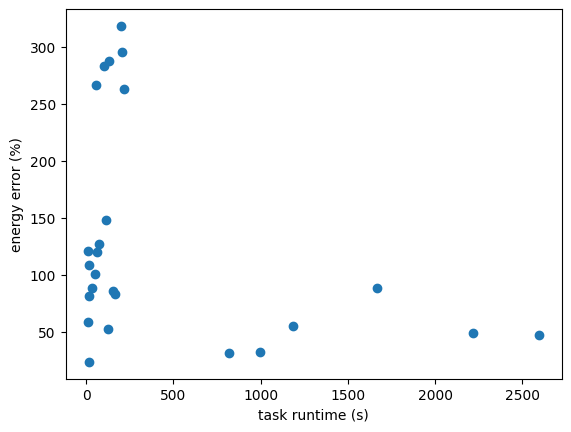

In [ ]:
# Analyse workflow properties

# aws-metal-c5d to HU cluster execution (worst task energy estimations?)
local_profile = wf_profiles[AWS_c5d]['node_profile']
target_profile = wf_profiles[HU_40]['node_profile']
aws_c5d_models, hu_reflector_models = create_prediction_model_with_reflections(wf_profiles[AWS_c5d]['executions'], LR, wf_executions[HU], 'nanoseq', local_profile, target_profile, (QR, LASSO), True)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['nanoseq'], wf_executions[HU]['nanoseq'][1], local_profile, hu_reflector_models)
workflow_types = data_df.groupby(['type']).size().reset_index(name='counts')
print('nanoseq')
print(workflow_types)
print('missing', len(missing_tasks))
print(runtime_vals, energy_vals)

plt.scatter(data_df['actual_t'].values, data_df['energy_error'].values)
plt.xlabel('task runtime (s)')
plt.ylabel('energy error (%)')
plt.show()

# i want to make the circles sized based on how many task instances there are? so i need to collect groups, e.g. the task and then the task's overall prediction error?
# collect task average runtime? colour by task?

rnaseq
                             type  counts
0              LinearRegression**     895
1  LinearRegression**REFLECT-ONLY      39
2                  Low Variance**       1
3                        Median**      82
4            Median**REFLECT-ONLY      14
5              Weak Linear Rel.**       1
missing 0
(230531.1971143729, 213996.31) (0.8510427182551704, 0.7185575718185939)


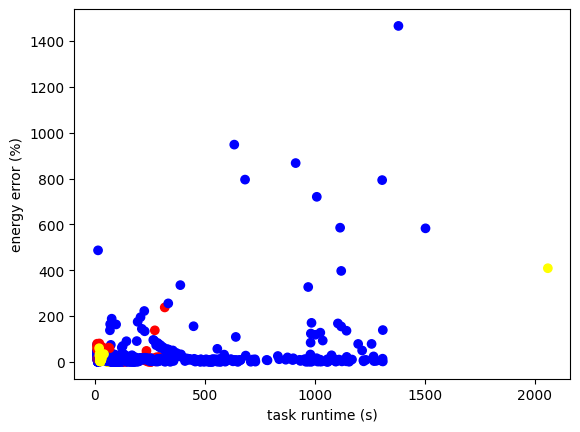

In [156]:
# aws-metal-c5d to HU cluster execution (worst task energy estimations?)
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['rnaseq'], wf_executions[HU]['rnaseq'][1], local_profile, hu_reflector_models)
workflow_types = data_df.groupby(['type']).size().reset_index(name='counts')
print('rnaseq')
print(workflow_types)
print('missing', len(missing_tasks))
print(runtime_vals, energy_vals)
colourmapping = {
    'LinearRegression**': 'blue',
    'LinearRegression**REFLECT-ONLY': 'red',
    'Low Variance**': 'green',
    'Median**': 'yellow',
    'Median**REFLECT-ONLY': 'red',
    'Weak Linear Rel.**': 'purple',
    # add missing types, e.g. without reflector data, and all the REFLECT-ONLY variants? make it based on using reflector data
}
data_df['colour'] = [colourmapping[row['type']] for _, row in data_df.iterrows()]

# figure out how to plot points based on the no. of instances of a task
plt.scatter(data_df['actual_t'].values, data_df['energy_error'].values, c=data_df['colour'])
plt.xlabel('task runtime (s)')
plt.ylabel('energy error (%)')
plt.show()

chipseq
                             type  counts
0              LinearRegression**    1234
1  LinearRegression**REFLECT-ONLY     133
2                    Low Variance     313
3                          Median      65
4                        Median**     315
5            Median**REFLECT-ONLY     165
6              Weak Linear Rel.**     132
missing 0
(407148.56628240366, 366469.733) (1.763687557200373, 1.5258990809704076)


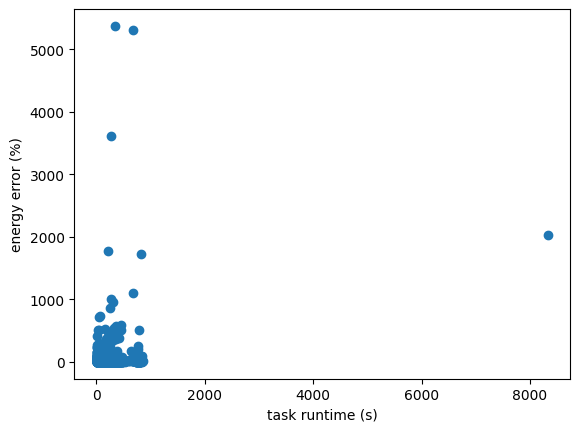

In [149]:
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['chipseq'], wf_executions[HU]['chipseq'][1], local_profile, hu_reflector_models)
workflow_types = data_df.groupby(['type']).size().reset_index(name='counts')
print('chipseq')
print(workflow_types)
print('missing', len(missing_tasks))
print(runtime_vals, energy_vals)

plt.scatter(data_df['actual_t'].values, data_df['energy_error'].values)
plt.xlabel('task runtime (s)')
plt.ylabel('energy error (%)')
plt.show()

atacseq
                             type  counts
0                LinearRegression      59
1              LinearRegression**      88
2  LinearRegression**REFLECT-ONLY       3
3                  Low Variance**       2
4                          Median       2
5                        Median**      30
missing 0
(29804.30081507004, 24907.591) (0.11436357418731344, 0.0793826833940606)


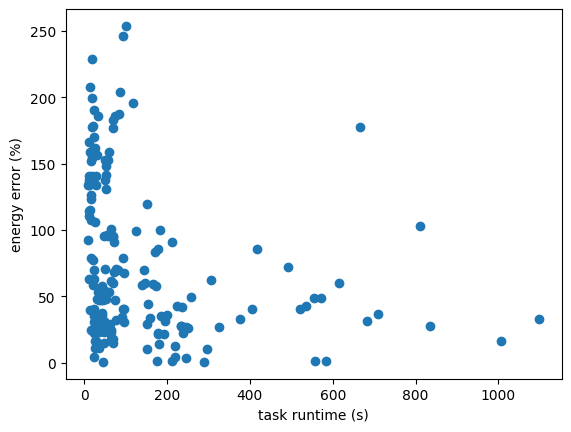

In [151]:
(_, _, _, ((task_runtime_error, task_energy_error, data, missing_tasks, data_df, runtime_vals, energy_vals))) = predict_wf(aws_c5d_models['atacseq'], wf_executions[HU]['atacseq'][1], local_profile, hu_reflector_models)
workflow_types = data_df.groupby(['type']).size().reset_index(name='counts')
print('atacseq')
print(workflow_types)
print('missing', len(missing_tasks))
print(runtime_vals, energy_vals)

plt.scatter(data_df['actual_t'].values, data_df['energy_error'].values)
plt.xlabel('task runtime (s)')
plt.ylabel('energy error (%)')
plt.show()